# Loading the model

In [6]:
import torch, torchvision, numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from google.colab import drive
drive.mount("/content/drive")
device = "cuda" if torch.cuda.is_available() else "cpu"
tf = transforms.Compose([
transforms.Resize(224),
transforms.ToTensor(),
transforms.Normalize([0.485, 0.456, 0.406],
[0.229, 0.224, 0.225]),
])
model = torchvision.models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)
model.load_state_dict(torch.load(
"/content/drive/MyDrive/eurosat_resnet50.pt", map_location=device))
model = model.to(device).eval()
print("model loaded on", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
model loaded on cpu


# Splitting the datset into 2000 images as a home pile

In [7]:
!pip install -q rasterio
from torch.utils.data import random_split, DataLoader, Subset
data = torchvision.datasets.EuroSAT(root="/content", download=True, transform=tf)
n = len(data)
g = torch.Generator().manual_seed(42)
train_set, val_set, test_set = random_split(
data, [int(n*0.7), int(n*0.15), n - int(n*0.7) - int(n*0.15)], generator=g)
home_dl = DataLoader(test_set, batch_size=64) # 4,050 home images
bank_dl = DataLoader(Subset(train_set, range(2000)), batch_size=64)
print("home pile:", len(test_set), "| bank:", 2000)

home pile: 4050 | bank: 2000


# Splitting forigen dataset into 2000 images pile

In [8]:
import rasterio
def load_geotiff(path):
  with rasterio.open(path) as src:
    img = src.read([1, 2, 3])
  img = np.transpose(img, (1, 2, 0))
  img = np.clip(img / np.quantile(img, 0.98), 0, 1)
  return (img * 255).astype(np.uint8)

AMAZON_PATH = "/content/drive/MyDrive/research2 (1)/amazon_2018.tif"
img18 = load_geotiff(AMAZON_PATH)
tile = 64
rows, cols = img18.shape[0]//tile, img18.shape[1]//tile
foreign_imgs = [img18[r*tile:(r+1)*tile, c*tile:(c+1)*tile]
for r in range(rows) for c in range(cols)]
print("foreign pile:", len(foreign_imgs), "patches")

foreign pile: 289 patches


# Get the 10 raw scores and 2048 measurements description

In [9]:
feat_net = nn.Sequential(*list(model.children())[:-1]).to(device).eval()

def collect_from_loader(dl):
    feats, logits, labels = [], [], []
    with torch.no_grad():
        for x, y in dl:
            f = feat_net(x.to(device)).flatten(1)
            feats.append(f.cpu()); logits.append(model.fc(f).cpu()); labels.append(y)
    return torch.cat(feats), torch.cat(logits), torch.cat(labels)

def collect_from_patches(patches):
    feats, logits = [], []
    with torch.no_grad():
        for i in range(0, len(patches), 64):
            batch = torch.stack([tf(Image.fromarray(p))
                                 for p in patches[i:i+64]]).to(device)
            f = feat_net(batch).flatten(1)
            feats.append(f.cpu()); logits.append(model.fc(f).cpu())
    return torch.cat(feats), torch.cat(logits)

home_feats, home_logits, _ = collect_from_loader(home_dl)
bank_feats, bank_logits, bank_labels = collect_from_loader(bank_dl)
foreign_feats, foreign_logits = collect_from_patches(foreign_imgs)
print(home_feats.shape, bank_feats.shape, foreign_feats.shape)

np.save("/content/drive/MyDrive/ood_home_feats.npy", home_feats.numpy())
np.save("/content/drive/MyDrive/ood_bank_feats.npy", bank_feats.numpy())
np.save("/content/drive/MyDrive/ood_foreign_feats.npy", foreign_feats.numpy())
print("signals saved to Drive")

torch.Size([4050, 2048]) torch.Size([2000, 2048]) torch.Size([289, 2048])
signals saved to Drive


# Testing all 4 functions

In [10]:
def alarm_confidence(logits):
    # low top-percentage -> high danger
    return (-F.softmax(logits, 1).max(1).values).numpy()

def alarm_mumble(logits):
    # all 10 raw scores weak ("mumbling") -> high danger
    return (-torch.logsumexp(logits, 1)).numpy()

# alarm 3: distance to the NEAREST class center (simple ruler version)
class_means = torch.stack([bank_feats[bank_labels == c].mean(0) for c in range(10)])

def alarm_center(feats):
    return torch.cdist(feats, class_means).min(1).values.numpy()

# alarm 4: distance to the 5th-nearest training dot
def alarm_knn(feats, k=5):
    d = torch.cdist(feats, bank_feats)
    return d.topk(k, largest=False).values[:, -1].numpy()

danger = {}
for name, fn, uses in [("confidence", alarm_confidence, "logits"),
                       ("mumble",     alarm_mumble,     "logits"),
                       ("center",     alarm_center,     "feats"),
                       ("knn",        alarm_knn,        "feats")]:
    if uses == "logits":
        danger[name] = (fn(home_logits), fn(foreign_logits))
    else:
        danger[name] = (fn(home_feats), fn(foreign_feats))

print("danger scores computed for all 4 alarms")

danger scores computed for all 4 alarms


# The grading

In [12]:
from sklearn.metrics import roc_auc_score
print(f"{'alarm':12s} {'separation':>10s} {'caught%':>9s}")
results = {}
for name, (h, f) in danger.items():
  y = np.r_[np.zeros(len(h)), np.ones(len(f))]
  s = np.r_[h, f]
  sep = roc_auc_score(y, s)
  thr = np.quantile(h, 0.95)
  caught = (f > thr).mean() * 100
  results[name] = (sep, caught)
  print(f"{name:12s} {sep:10.3f} {caught:8.1f}%")

alarm        separation   caught%
confidence        0.911     54.0%
mumble            0.854     49.5%
center            0.864     31.8%
knn               0.775     19.4%


# Plot histograms

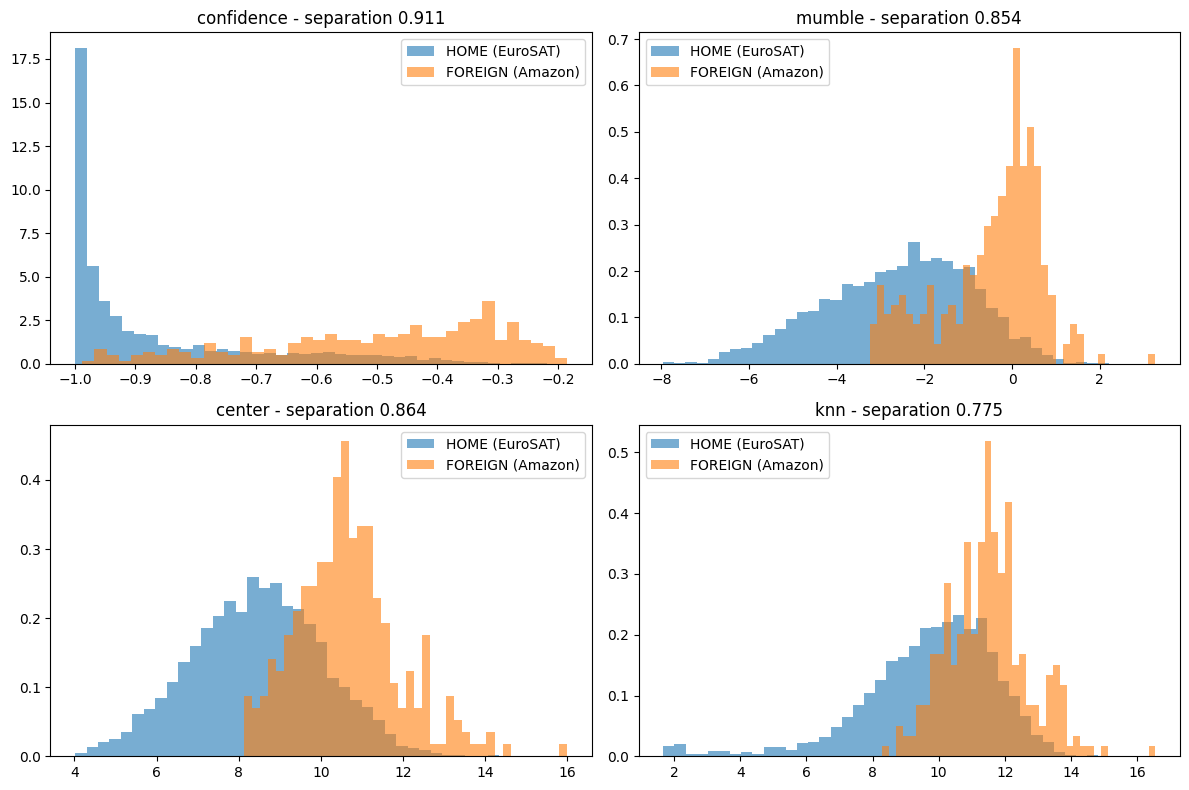

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for i, (name, (h, f)) in enumerate(danger.items()):
  a = ax[i//2, i%2]
  a.hist(h, bins=40, alpha=0.6, label="HOME (EuroSAT)", density=True)
  a.hist(f, bins=40, alpha=0.6, label="FOREIGN (Amazon)", density=True)
  a.set_title(f"{name} - separation {results[name][0]:.3f}")
  a.legend()
plt.tight_layout(); plt.show()

# Re testing best performing function

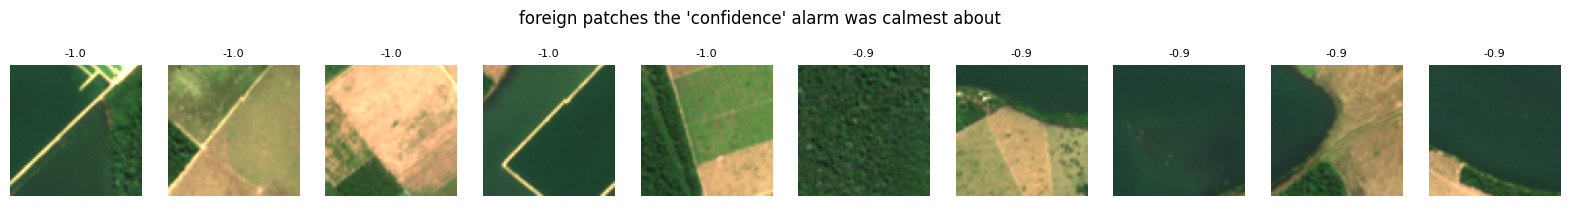

In [14]:
best = max(results, key=lambda k: results[k][0])
f_scores = danger[best][1]
sleepiest = np.argsort(f_scores)[:10] # lowest danger = most slept-through
fig, ax = plt.subplots(1, 10, figsize=(20, 2.5))
for i, idx in enumerate(sleepiest):
  ax[i].imshow(foreign_imgs[idx]); ax[i].axis("off")
  ax[i].set_title(f"{f_scores[idx]:.1f}", fontsize=8)
plt.suptitle(f"foreign patches the '{best}' alarm was calmest about")
plt.show()